# Solutions to notebook 6: Boundary value problems

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/06_boundary_value_problems.ipynb)

Worked solutions to the exercises at the end of [notebook 6](../notebooks/06_boundary_value_problems.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 6: cheb(N) (first met in notebook 5) and clenshaw_curtis(N) (explained in notebook 10)
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

## Exercise 1

A rod of length 1 joins two walls. Its temperature excess satisfies $\theta'' = m^2\theta$
on $0 \le x \le 1$ with $\theta(0) = 1$, $\theta(1) = 0.2$ and $m = 3$. Map the Chebyshev
points to $[0, 1]$ (the second-derivative matrix is multiplied by 4), solve with $N = 16$
and compute the heat flow into the rod at the hot end, $-\theta'(0)$. Check against the
exact solution, a combination of $\sinh mx$ and $\sinh m(1-x)$.

With $x = (\xi + 1)/2$ each derivative with respect to $x$ is twice the derivative with respect
to $\xi$, so the first-derivative matrix is $2D$ and the second-derivative matrix is $4D^2$.
The points still run from right to left: index 0 is $x = 1$, the cold end with
$\theta = 0.2$, and index $N$ is $x = 0$, the hot end with $\theta = 1$. The known boundary
values move to the right-hand side as in 6.2. The exact solution is
$\theta = \big[\sinh m(1 - x) + 0.2\sinh mx\big]/\sinh m$, so that
$-\theta'(0) = m\,(\cosh m - 0.2)/\sinh m$.

In [3]:
m, N = 3.0, 16
D, xi = cheb(N)
x = (xi + 1) / 2                                                   # index 0 is x = 1, index N is x = 0
Dx = 2 * D
A = Dx @ Dx - m**2 * np.eye(N + 1)

theta = np.zeros(N + 1)
theta[0], theta[N] = 0.2, 1.0                                      # cold end x = 1, hot end x = 0
boundary = [0, N]
theta[1:N] = np.linalg.solve(A[1:N, 1:N], -A[1:N, boundary] @ theta[boundary])
heat_flow = -(Dx @ theta)[N]                                       # row N is the hot end x = 0

theta_exact = (np.sinh(m * (1 - x)) + 0.2 * np.sinh(m * x)) / np.sinh(m)
heat_flow_exact = m * (np.cosh(m) - 0.2) / np.sinh(m)
print(f"largest error in θ: {np.abs(theta - theta_exact).max():.1e}")
print(f"heat flow into the rod, -θ'(0) = {heat_flow:.10f}   exact {heat_flow_exact:.10f}")

largest error in θ: 3.6e-15
heat flow into the rod, -θ'(0) = 2.9550165281   exact 2.9550165281


In [4]:
# verify: the profile and the heat flow against the exact solution
assert np.abs(theta - theta_exact).max() < 1e-12
assert abs(heat_flow - heat_flow_exact) < 1e-10

**Answer.** The heat flow into the rod at the hot end is $-\theta'(0) = 2.9550165281$, in
agreement with the exact value $m(\cosh m - 0.2)/\sinh m$ to all ten decimals shown, and the
profile is correct to $4\times10^{-15}$ with 17 points. The only places to go wrong are the
factor 2 per derivative from the change of interval and the ordering: the hot end $x = 0$ is
the **last** grid point.

## Exercise 2

Steady convection and diffusion of a solute between two reservoirs obeys
$u'' - Pe\,u' = 0$ on $[-1, 1]$ with $u(-1) = 0$ and $u(1) = 1$. The exact solution is
$u = \big(e^{Pe\,(x-1)} - e^{-2Pe}\big)/\big(1 - e^{-2Pe}\big)$, which has a boundary layer of thickness
$1/Pe$ at $x = 1$. For $Pe = 10$ and $Pe = 50$ find the smallest even $N$ that gives a largest
error below $10^{-8}$. Plot the solution for $Pe = 50$ with $N = 16$ and describe what an
under-resolved spectral solution looks like.

The operator is $A = D^2 - Pe\,D$. The boundary value $u(1) = 1$ belongs to index 0 and
$u(-1) = 0$ to index $N$, so only column 0 of $A$ moves to the right-hand side. The layer at
$x = 1$ has thickness $1/Pe$, and the grid must put a few points inside it before the error
starts to fall.

Pe = 10: smallest even N = 20, error 2.9e-09, grid points inside the layer 1 - 1/Pe < x < 1: 2
Pe = 50: smallest even N = 42, error 4.9e-09, grid points inside the layer 1 - 1/Pe < x < 1: 2
Pe = 50, N = 16: largest error 0.033, most negative value -0.018, grid points inside the layer: 1


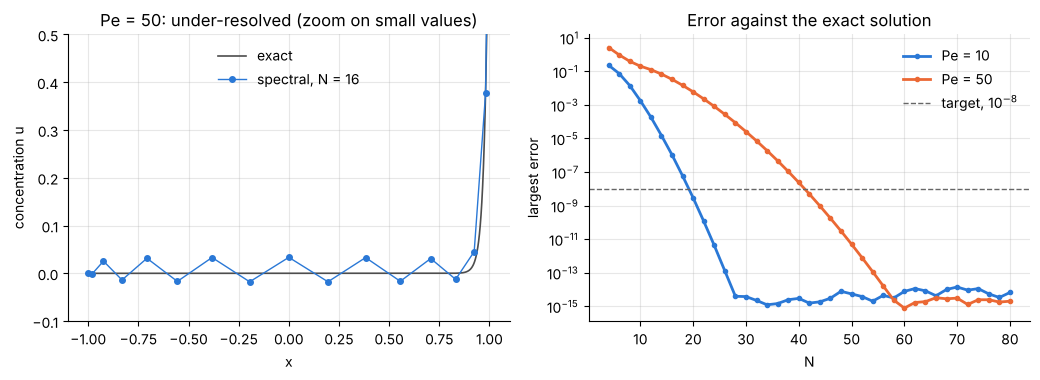

In [5]:
def convection_diffusion(Pe, N):
    """Solve u'' - Pe u' = 0, u(-1) = 0, u(1) = 1. Returns x, u and the largest error."""
    D, x = cheb(N)
    A = D @ D - Pe * D
    u = np.zeros(N + 1)
    u[0] = 1.0                                                     # index 0 is x = +1; u[N] = 0 is x = -1
    u[1:N] = np.linalg.solve(A[1:N, 1:N], -A[1:N, 0] * u[0])
    exact = (np.exp(Pe * (x - 1)) - np.exp(-2 * Pe)) / (1 - np.exp(-2 * Pe))
    return x, u, np.abs(u - exact).max()

N_even = np.arange(4, 81, 2)
errors, smallest_N = {}, {}
for Pe in (10, 50):
    errors[Pe] = np.array([convection_diffusion(Pe, N)[2] for N in N_even])
    smallest_N[Pe] = N_even[errors[Pe] < 1e-8][0]
    x_N = cheb(smallest_N[Pe])[1]
    print(f"Pe = {Pe}: smallest even N = {smallest_N[Pe]}, error {errors[Pe][N_even == smallest_N[Pe]][0]:.1e}, "
          f"grid points inside the layer 1 - 1/Pe < x < 1: {np.count_nonzero((x_N > 1 - 1 / Pe) & (x_N < 1))}")

x16, u16, error16 = convection_diffusion(50, 16)
print(f"Pe = 50, N = 16: largest error {error16:.3f}, most negative value {u16.min():.3f}, "
      f"grid points inside the layer: {np.count_nonzero((x16 > 0.98) & (x16 < 1))}")

fine = np.linspace(-1, 1, 1000)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].plot(fine, (np.exp(50 * (fine - 1)) - np.exp(-100)) / (1 - np.exp(-100)), color="0.3", lw=1.2, label="exact")
axes[0].plot(x16, u16, "o-", ms=4, lw=1, label="spectral, N = 16")
axes[0].set(xlabel="x", ylabel="concentration u", ylim=(-0.1, 0.5), title="Pe = 50: under-resolved (zoom on small values)")
axes[0].legend(frameon=False, loc="upper center")
for Pe in (10, 50):
    axes[1].semilogy(N_even, errors[Pe], "o-", ms=3, label=f"Pe = {Pe}")
axes[1].axhline(1e-8, color="0.4", lw=1, ls="--", label="target, 10$^{-8}$")
axes[1].set(xlabel="N", ylabel="largest error", title="Error against the exact solution")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()

In [6]:
# verify: the errors are measured against the exact solution; the N found are the first even N below
# the target; the under-resolved solution oscillates in sign where the exact solution is positive
for Pe in (10, 50):
    assert convection_diffusion(Pe, smallest_N[Pe])[2] < 1e-8 <= convection_diffusion(Pe, smallest_N[Pe] - 2)[2]
assert smallest_N[10] < smallest_N[50] < 5 * smallest_N[10]        # five times thinner layer, far fewer than five times the points
assert error16 > 0.01 and u16.min() < -0.01
assert np.count_nonzero(np.diff(np.sign(np.diff(u16[2:-1]))) != 0) >= 10      # a sawtooth: the slope changes sign at almost every point

**Answer.** The smallest even $N$ with a largest error below $10^{-8}$ is $N = 20$ for
$Pe = 10$ and $N = 42$ for $Pe = 50$. A layer five times thinner costs about twice the points,
not five times, because the Chebyshev spacing at the wall shrinks like $1/N^2$; in both cases
the grid that reaches the target has just two points strictly inside the layer of thickness
$1/Pe$. With $Pe = 50$ and $N = 16$ only one point lies inside the layer, the largest error is
0.033, and the solution shows the mark of an under-resolved spectral computation: a sawtooth
that changes direction at every grid point and fills the **whole** interval, here with
amplitude 0.03 and negative concentrations down to $-0.018$, far from the layer that causes
it. An upwind finite difference solution would smear the layer over a few cells, and a central
one would also oscillate (its cell Péclet number is above 2), but with wiggles that die away
from the layer. The spectral sawtooth does not die away: a spectral solution is global, so its
errors are global too. The remedy is more points: the oscillation is a warning, and it
disappears as soon as the layer is resolved.

## Exercise 3

For a second-order reaction in the catalyst slab the equation becomes
$\theta'' = \phi^2\theta^2$, $\theta(\pm1) = 1$. Solve it by Newton's method for $\phi = 2$
with $N = 32$, starting from $\theta = 1$, and print the residuals. Report the effectiveness
factor $\eta = \theta'(1)/\phi^2$ and check your solution with the identity
$\theta'(1)^2 = \tfrac23\phi^2\big(1 - \theta(0)^3\big)$, which follows from multiplying the
equation by $\theta'$ and integrating.

The residual at the interior points is $\mathbf{F}(\boldsymbol\theta) = D^2\boldsymbol\theta - \phi^2\boldsymbol\theta^2$
and its Jacobian is $J = D^2 - 2\phi^2\operatorname{diag}(\boldsymbol\theta)$. The starting guess
$\theta = 1$ already has the right boundary values, so every Newton correction is zero at the
boundary and only the interior block of $J$ is needed.

In [7]:
def second_order_slab(phi, N, steps=8):
    """Newton iteration for θ'' = φ² θ², θ(±1) = 1. Returns D, x, θ and the residual history."""
    D, x = cheb(N)
    D2 = D @ D
    theta = np.ones(N + 1)                                         # satisfies the boundary conditions
    history = []
    for _ in range(steps):
        F = (D2 @ theta - phi**2 * theta**2)[1:N]
        history.append(np.abs(F).max())
        J = D2[1:N, 1:N] - 2 * phi**2 * np.diag(theta[1:N])
        theta[1:N] -= np.linalg.solve(J, F)
    return D, x, theta, history

phi, N = 2.0, 32
D, x, theta, history = second_order_slab(phi, N)
for step, residual in enumerate(history):
    print(f"step {step}:  largest residual = {residual:.1e}")

gradient = (D @ theta)[0]                                          # row 0 is the face x = +1
eta = gradient / phi**2
centre = theta[N // 2]                                             # N even: the middle point is x = 0
print(f"\nη = {eta:.10f}   centre concentration θ(0) = {centre:.10f}")
print(f"θ'(1)² = {gradient**2:.12f}   (2/3) φ² (1 - θ(0)³) = {2 / 3 * phi**2 * (1 - centre**3):.12f}")
print(f"first-order reaction with the same φ: η = {np.tanh(phi) / phi:.6f}")

step 0:  largest residual = 4.0e+00
step 1:  largest residual = 7.8e-01
step 2:  largest residual = 4.7e-02
step 3:  largest residual = 1.7e-04
step 4:  largest residual = 1.9e-09
step 5:  largest residual = 1.2e-11
step 6:  largest residual = 3.0e-12
step 7:  largest residual = 1.2e-11

η = 0.3900075847   centre concentration θ(0) = 0.4437227240
θ'(1)² = 2.433694658293   (2/3) φ² (1 - θ(0)³) = 2.433694658293
first-order reaction with the same φ: η = 0.482014


In [8]:
# verify: quadratic convergence of Newton's method, the first integral of the equation (an identity the
# discretization knows nothing about), and the same η from a finer grid
assert all(history[k + 1] < 0.2 * history[k] ** 2 for k in range(4)) and history[5] < 1e-9
assert abs(gradient**2 - 2 / 3 * phi**2 * (1 - centre**3)) < 1e-10
D48, x48, theta48, _ = second_order_slab(phi, 48)
assert abs((D48 @ theta48)[0] / phi**2 - eta) < 1e-10

**Answer.** Newton's method converges quadratically, with residuals 4.0, 0.78,
$4.7\times10^{-2}$, $1.7\times10^{-4}$, $1.9\times10^{-9}$, and then stays at the rounding
level of about $10^{-11}$. The effectiveness factor is $\eta = 0.390008$ and the centre
concentration is $\theta(0) = 0.443723$. Both sides of the identity equal 2.433694658293, an
agreement to twelve decimals. A second-order reaction uses the slab less effectively than a
first-order reaction with the same $\phi$ ($\eta = 0.482$): its rate is $\phi^2\theta^2$
against $\phi^2\theta$, and both are referred to the same rate $\phi^2$ at the surface
concentration, so wherever the reactant is depleted the second-order rate is the smaller of
the two.

## Exercise 4

With the full Arrhenius rate the thermal explosion problem is
$u'' + \delta\exp\!\big(u/(1 + \varepsilon u)\big) = 0$, $u(\pm1) = 0$, where $\varepsilon$
is the ambient temperature in units of the activation temperature. Adapt `bratu_centre` to
this heat source and trace $\delta$ against $u(0)$ for $0.05 \le u(0) \le 60$ with $N = 40$. For
$\varepsilon = 0.2$ find both turning points (ignition and extinction) to four digits. For
$\varepsilon = 0.3$ show that there is no turning point, and say what that means for the
material.

Write the heat source as $g(u) = \exp\!\big(u/(1 + \varepsilon u)\big)$. Two lines of
`bratu_centre` change: the residual uses $g(\mathbf{u})$, which is also the last column
$\partial\mathbf{F}/\partial\delta$ of the Jacobian, and the diagonal of the Jacobian uses
$g'(u) = g(u)/(1 + \varepsilon u)^2$. The stopping tolerance is relaxed from $10^{-12}$ to
$10^{-9}$, because with $u$ up to 60 the product $D^2\mathbf{u}$ carries rounding errors of
about $10^{-10}$. The centre temperatures are spaced geometrically, since the curve has
structure at both small and large $u(0)$.

In [9]:
def arrhenius_centre(u_c, eps, N=40, guess=None):
    """Solve u'' + δ exp(u/(1 + εu)) = 0, u(±1) = 0 with the centre value u(0) = u_c prescribed. Returns δ, x, u."""
    D, x = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    mid = N // 2 - 1                                               # position of x = 0 among the interior points
    u, delta = (u_c * (1 - x[1:N] ** 2), u_c / (1 + u_c)) if guess is None else guess
    J = np.zeros((N, N))
    J[N - 1, mid] = 1.0
    for _ in range(40):
        g = np.exp(u / (1 + eps * u))
        F = np.append(D2 @ u + delta * g, u[mid] - u_c)
        if np.abs(F).max() < 1e-9:
            break
        J[:N - 1, :N - 1] = D2 + delta * np.diag(g / (1 + eps * u) ** 2)
        J[:N - 1, N - 1] = g
        step = np.linalg.solve(J, -F)
        u, delta = u + step[:-1], delta + step[-1]
    return delta, x, np.concatenate(([0.0], u, [0.0]))

uc_values = np.geomspace(0.05, 60, 300)
curves = {}
for eps in (0.2, 0.3):
    delta_values, guess = [], None
    for u_c in uc_values:                                          # each solution is the starting guess for the next
        delta, x, u = arrhenius_centre(u_c, eps, guess=guess)
        delta_values.append(delta)
        guess = (u[1:-1], delta)
    curves[eps] = np.array(delta_values)

# turning points for ε = 0.2: δ(u_c) has a local maximum (ignition) followed by a local minimum (extinction)
turns = np.nonzero(np.diff(np.sign(np.diff(curves[0.2]))))[0] + 1  # indices where δ changes direction
print("ε = 0.2: δ changes direction near u(0) =", np.round(uc_values[turns], 2))
ignition = minimize_scalar(lambda u_c: -arrhenius_centre(u_c, 0.2)[0], bounds=(uc_values[turns[0] - 1], uc_values[turns[0] + 1]),
                           method="bounded", options={"xatol": 1e-8})
extinction = minimize_scalar(lambda u_c: arrhenius_centre(u_c, 0.2)[0], bounds=(uc_values[turns[1] - 1], uc_values[turns[1] + 1]),
                             method="bounded", options={"xatol": 1e-8})
uc_ign, delta_ign, uc_ext, delta_ext = ignition.x, -ignition.fun, extinction.x, extinction.fun
print(f"ignition:    δ = {delta_ign:.6f} at u(0) = {uc_ign:.4f}")
print(f"extinction:  δ = {delta_ext:.6f} at u(0) = {uc_ext:.4f}")
print(f"ε = 0.3: smallest increase of δ between neighbouring points of the curve = {np.diff(curves[0.3]).min():.2e}")

ε = 0.2: δ changes direction near u(0) = [ 2.33 15.53]
ignition:    δ = 1.161980 at u(0) = 2.3541
extinction:  δ = 0.877482 at u(0) = 15.4141
ε = 0.3: smallest increase of δ between neighbouring points of the curve = 2.21e-03


For an independent check, solve the same problem with no matrices at all. In the stretched
coordinate $s = \sqrt\delta\,x$ the equation is $u_{ss} = -g(u)$, with no parameter in it. Start
at the centre with $u = u_c$, $u_s = 0$, integrate as an initial value problem until $u$ falls to
zero at some $s^*$. That point is the wall $x = 1$, so $\delta = s^{*2}$. The integrator is
`scipy.integrate.solve_ivp`, which has not appeared in the lessons: it steps an initial value
problem forward with error control, and the `events` function stops it where $u$ crosses zero.

In [10]:
def delta_by_shooting(u_c, eps):
    rhs = lambda s, y: [y[1], -np.exp(y[0] / (1 + eps * y[0]))]
    wall = lambda s, y: y[0]
    wall.terminal = True
    solution = solve_ivp(rhs, (0, 50), [u_c, 0.0], events=wall, method="DOP853", rtol=1e-12, atol=1e-13)
    return solution.t_events[0][0] ** 2

# verify: δ(u(0)) against shooting along both curves and at the turning points, the turning points
# against a finer grid, the limit ε = 0 against δ_c = 0.878458 of 6.5, and no turning point for ε = 0.3
for eps in (0.2, 0.3):
    sample = np.arange(0, len(uc_values), 23)
    shot = np.array([delta_by_shooting(u_c, eps) for u_c in uc_values[sample]])
    assert np.abs(curves[eps][sample] / shot - 1).max() < 1e-8
assert abs(delta_ign - delta_by_shooting(uc_ign, 0.2)) < 1e-8 and abs(delta_ext - delta_by_shooting(uc_ext, 0.2)) < 1e-8
assert delta_by_shooting(uc_ign - 0.1, 0.2) < delta_ign > delta_by_shooting(uc_ign + 0.1, 0.2)      # a maximum
assert delta_by_shooting(uc_ext - 0.5, 0.2) > delta_ext < delta_by_shooting(uc_ext + 0.5, 0.2)      # a minimum
assert abs(arrhenius_centre(uc_ign, 0.2, N=60)[0] - delta_ign) < 1e-9 and abs(arrhenius_centre(uc_ext, 0.2, N=60)[0] - delta_ext) < 1e-9
assert abs(arrhenius_centre(1.186842, 0.0)[0] - 0.878458) < 1e-6
assert np.all(np.diff(curves[0.3]) > 0)
assert np.all(np.diff([delta_by_shooting(u_c, 0.3) for u_c in uc_values[::10]]) > 0)

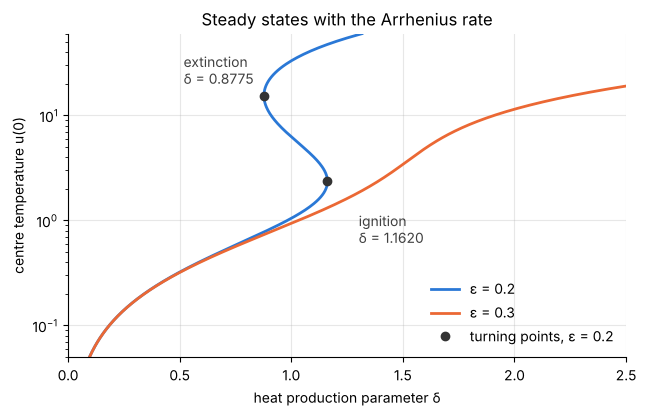

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for eps in (0.2, 0.3):
    ax.semilogy(curves[eps], uc_values, label=f"ε = {eps}")
ax.plot([delta_ign, delta_ext], [uc_ign, uc_ext], "o", color="0.2", label="turning points, ε = 0.2")
ax.annotate(f"ignition\nδ = {delta_ign:.4f}", xy=(delta_ign, uc_ign), xytext=(delta_ign + 0.14, uc_ign * 0.26), color="0.25")
ax.annotate(f"extinction\nδ = {delta_ext:.4f}", xy=(delta_ext, uc_ext), xytext=(delta_ext - 0.36, uc_ext * 1.3), color="0.25")
ax.set(xlabel="heat production parameter δ", ylabel="centre temperature u(0)", xlim=(0, 2.5), ylim=(0.05, 60),
       title="Steady states with the Arrhenius rate")
ax.legend(frameon=False, loc="lower right");

**Answer.** For $\varepsilon = 0.2$ the curve is S-shaped, with two turning points:
**ignition** at $\delta = 1.162$, where $u(0) = 2.354$, and **extinction** at
$\delta = 0.8775$, where $u(0) = 15.41$. Between these two values of $\delta$ there are three
steady states, a cool one, a hot one and an unstable one between them. A slab on the cool
branch jumps to the hot branch when $\delta$ is raised past 1.162 and does not come back until
$\delta$ is lowered below 0.8775: the system has hysteresis. Compared with the exponential
source of 6.5, the finite activation temperature raises the ignition limit from 0.8785 to
1.162 and replaces unbounded runaway by a hot steady state. For $\varepsilon = 0.3$,
$\delta$ increases steadily with $u(0)$ along the whole curve, so there is no turning point
and exactly one steady state for every $\delta$. Such a material has no ignition limit and no
critical size: as the slab is made thicker or its surroundings warmer the centre temperature
rises steeply but continuously, with no jump. The loss of criticality happens at a value of
$\varepsilon$ between 0.2 and 0.3.

## Exercise 5

A rectangular duct has sides $4a$ and $2a$. Solve $\nabla^2 u = -1$ on
$[-2, 2]\times[-1, 1]$ with $u = 0$ on the walls by rescaling the $x$ derivative, and
compute $f\,Re$ based on the hydraulic diameter. The tabulated value is 15.548.

Scale lengths by $a$, so that the duct is $[-2, 2]\times[-1, 1]$, and write $x = 2\xi$ with
$-1 \le \xi \le 1$. Then $\partial^2/\partial x^2 = \tfrac14\,\partial^2/\partial\xi^2$, and the
Laplacian of 6.6 becomes $L = I\otimes\tfrac14\tilde D^2 + \tilde D^2\otimes I$, with the same
ordering of the unknowns (`U[i, j]` $= u(x_j, y_i)$, the $x$ index running fastest). The flow
rate picks up a factor 2 from $dx = 2\,d\xi$. The area is 8 and the perimeter 12, so
$D_h = 4\times8/12 = \tfrac83$ and the mean velocity is $\bar u = Q/8$. From 6.7,
$f\,Re = G D_h^2/(2\mu\bar w)$, which in the scaled variables is

$$f\,Re = \frac{D_h^2}{2\bar u} = \frac{256}{9\,Q} .$$

In [12]:
def rectangular_duct(N, half_width=2.0):
    """Velocity on the interior points and flow rate for the duct [-half_width, half_width] x [-1, 1]."""
    D, xi = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    I = np.eye(N - 1)
    L = np.kron(I, D2 / half_width**2) + np.kron(D2, I)            # x = half_width ξ: the x derivative is rescaled
    U = np.linalg.solve(L, -np.ones((N - 1) ** 2)).reshape(N - 1, N - 1)
    w = clenshaw_curtis(N)[1][1:N]                                 # interior weights; the wall values of u are zero
    return xi, U, half_width * (w @ U @ w)                         # dx = half_width dξ

hydraulic_diameter = 4 * 8 / 12
print("  N   flow rate Q      f Re")
duct = {}
for N in (8, 16, 24, 32):
    xi, U, Q = rectangular_duct(N)
    duct[N] = (Q, hydraulic_diameter**2 / (2 * Q / 8))
    print(f"{N:3d}   {Q:.8f}   {duct[N][1]:.6f}")

# the classical series solution for a rectangle with half-sides 2 and 1
n = np.arange(1, 400, 2)
Q_series = 4 / 3 * 2 * (1 - 192 / (2 * np.pi**5) * np.sum(np.tanh(n * np.pi) / n**5))
print(f"series {Q_series:.8f}   {256 / (9 * Q_series):.6f}")

  N   flow rate Q      f Re
  8   1.82948515   15.547786
 16   1.82945354   15.548055
 24   1.82945342   15.548056
 32   1.82945342   15.548056
series 1.82945342   15.548056


In [13]:
# verify: against the tabulated value, against the Fourier series solution, and, with half_width = 1,
# against the square duct of 6.7 (Q = 0.562308)
Q, fRe = duct[32]
assert abs(fRe - 15.548) < 5e-4
assert abs(Q - Q_series) < 1e-8
assert abs(rectangular_duct(32, half_width=1.0)[2] - 0.562308) < 5e-7

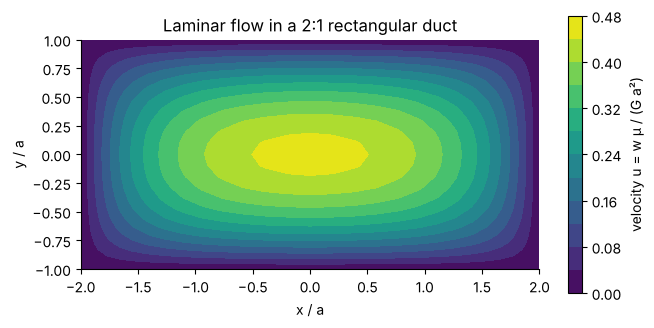

In [14]:
N = 32
U_full = np.zeros((N + 1, N + 1))
U_full[1:N, 1:N] = U                                               # put the zero wall values back for plotting
fig, ax = plt.subplots(figsize=(7.4, 3.6))
filled = ax.contourf(2 * xi, xi, U_full, levels=np.linspace(0, 0.48, 13), cmap="viridis")
fig.colorbar(filled, ax=ax, label="velocity u = w μ / (G a²)")
ax.set(xlabel="x / a", ylabel="y / a", aspect="equal", title="Laminar flow in a 2:1 rectangular duct")
ax.grid(False)

**Answer.** $Q = 1.829453$ in units of $Ga^4/\mu$, and
$f\,Re = 256/(9Q) = 15.5481$, which rounds to the tabulated 15.548. The flow rate agrees with
the Fourier series solution to eight decimals, and $N = 16$ already gives six digits of
$f\,Re$. The value lies between 14.227 for the square and 24 for flow between parallel
plates: the flatter the duct, the further the pipe value of 16 is from the truth. The only
changes to the square duct code are the factor $\tfrac14$ on the $x$ derivative, the factor 2
on the integral, and the hydraulic diameter.